# Lecture 5 — Class Exercise
## Distribution Charts: Airbnb London

> **Push to:** `week05/lecture05_exercise.ipynb`

**Rules:**
1. Cap price outliers at 95th percentile — annotate this
2. Every chart has a **median/mean reference line** with annotation
3. Insight title names the distribution shape or key finding
4. Colour has meaning — don't use colour just for decoration

---


In [1]:
import pandas as pd
import plotly.express as px
import numpy as np

# Dataset: Airbnb London Listings

df = pd.read_csv('../data/airbnb_london.csv')
print(f"Loaded: {len(df)} listings")
print(df.describe().round(1))


Loaded: 2500 listings
        price  minimum_nights  number_of_reviews  availability_365  \
count  2500.0          2500.0             2500.0            2500.0   
mean    148.6            14.8              147.9             183.7   
std     110.9             8.4               86.3             105.5   
min      20.5             1.0                0.0               0.0   
25%      71.7             8.0               74.0              92.0   
50%     117.5            15.0              145.0             182.0   
75%     188.9            22.0              222.2             277.0   
max    1032.4            29.0              299.0             364.0   

       reviews_per_month  
count             2500.0  
mean                 2.0  
std                  2.0  
min                  0.0  
25%                  0.6  
50%                  1.4  
75%                  2.8  
max                 15.2  


In [2]:
p95 = df['price'].quantile(0.95)
df_cap = df[df['price'] <= p95]
print(f"95th percentile price: £{p95:.0f}")
print(df_cap.groupby('room_type')['price'].describe().round(1))


95th percentile price: £373
                  count   mean   std   min    25%    50%    75%    max
room_type                                                             
Entire home/apt  1251.0  176.3  75.7  28.0  119.6  163.4  223.5  372.6
Private room      942.0   87.3  39.5  20.9   59.0   78.6  106.0  277.9
Shared room       182.0   46.3  14.1  20.5   36.8   44.1   54.3   92.8


## Task 1 — Histogram: price by room type (overlapping distributions)

**What to build:** A histogram showing price distributions for **Entire home/apt vs Private room** (exclude Shared room — too few observations) overlaid on the same chart.

**Requirements:**
- Both room types on the same chart (use `color='room_type'`)
- `barmode='overlay'` with `opacity=0.6` so both distributions are visible
- A vertical line for the median of EACH room type, differently coloured
- Insight title comparing the two distributions

> 💡 `df_cap[df_cap['room_type'].isin(['Entire home/apt','Private room'])]`


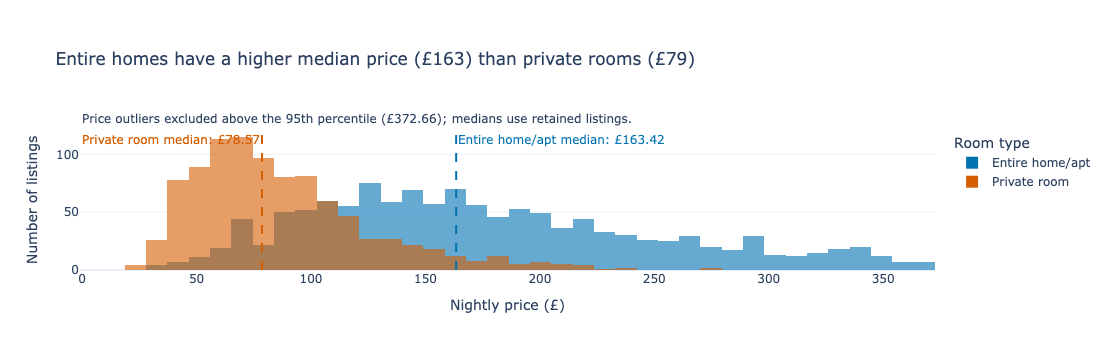

In [3]:
# Task 1
# YOUR CODE HERE

room_types = ['Entire home/apt', 'Private room']
prices = df_cap[df_cap['room_type'].isin(room_types)]
colours = {'Entire home/apt': '#0072B2', 'Private room': '#D55E00'}
medians = prices.groupby('room_type')['price'].median()
fig1 = px.histogram(
    prices, x='price', color='room_type', nbins=40,
    barmode='overlay', opacity=0.6, color_discrete_map=colours,
    category_orders={'room_type': room_types},
    labels={'price': 'Nightly price (£)', 'room_type': 'Room type'},
    title=f'Entire homes have a higher median price (£{medians[room_types[0]]:.0f}) than private rooms (£{medians[room_types[1]]:.0f})'
)
for room, position in zip(room_types, ['top right', 'top left']):
    fig1.add_vline(
        x=medians[room], line_dash='dash', line_color=colours[room],
        annotation_text=f'{room} median: £{medians[room]:.2f}',
        annotation_position=position, annotation_font_color=colours[room]
    )
fig1.update_traces(xbins=dict(start=0, end=float(p95), size=float(p95) / 40))
fig1.update_layout(template='plotly_white', yaxis_title='Number of listings',
                   margin=dict(t=130, b=90), legend_title_text='Room type')
fig1.add_annotation(x=0, y=1.15, xref='paper', yref='paper', showarrow=False,
                    text=f'Price outliers excluded above the 95th percentile (£{p95:.2f}); medians use retained listings.')
fig1.show()



## Task 2 — Box plot: listing activity by borough

**What to build:** A **horizontal box plot** comparing listing activity (reviews per month) across London boroughs — reviews per month is a proxy for how frequently a listing is booked.

**Requirements:**
- Horizontal orientation (borough names are long)
- Sorted by median reviews per month (most active at top)
- Highlight the **two most active** boroughs in a different colour
- Outliers shown as individual points
- Insight title naming the two busiest boroughs

> 💡 Some listings have zero reviews — these are new or inactive listings. Filter them out with before plotting

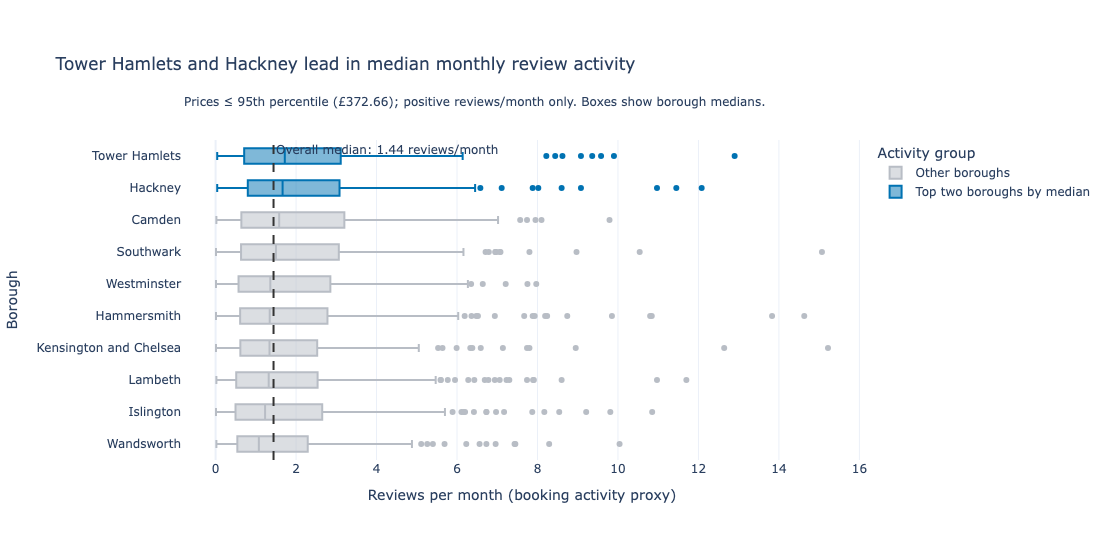

Highest median activity (reviews/month):
neighbourhood
Tower Hamlets    1.720
Hackney          1.665


In [4]:
# Task 2
# YOUR CODE HERE

active = df_cap[df_cap['reviews_per_month'].gt(0)].copy()
borough_medians = active.groupby('neighbourhood')['reviews_per_month'].median().sort_values(ascending=False)
borough_order = borough_medians.index.tolist()
top_two = borough_order[:2]
active['Activity group'] = np.where(active['neighbourhood'].isin(top_two),
                                    'Top two boroughs by median', 'Other boroughs')
fig2 = px.box(
    active, x='reviews_per_month', y='neighbourhood', orientation='h',
    color='Activity group', points='outliers',
    color_discrete_map={'Top two boroughs by median': '#0072B2', 'Other boroughs': '#B8BDC5'},
    category_orders={'neighbourhood': borough_order},
    labels={'reviews_per_month': 'Reviews per month (booking activity proxy)', 'neighbourhood': 'Borough'},
    title=f'{top_two[0]} and {top_two[1]} lead in median monthly review activity'
)
overall_median = active['reviews_per_month'].median()
fig2.add_vline(x=overall_median, line_dash='dash', line_color='#333333',
               annotation_text=f'Overall median: {overall_median:.2f} reviews/month',
               annotation_position='top right')
fig2.update_yaxes(categoryorder='array', categoryarray=borough_order, autorange='reversed')
fig2.update_layout(template='plotly_white', height=max(550, 30 * len(borough_order)),
                   margin=dict(t=140, b=90), boxmode='overlay')
fig2.add_annotation(x=0, y=1.15, xref='paper', yref='paper', showarrow=False,
                    text=f'Prices ≤ 95th percentile (£{p95:.2f}); positive reviews/month only. Boxes show borough medians.')
fig2.show()
print('Highest median activity (reviews/month):')
print(borough_medians.head(2).round(3).to_string())